
# Análisis exploratorio del dataset MVTec AD

## Dataset

**Fuente:** [MVTec AD](https://www.mvtec.com/research-teaching/datasets/mvtec-ad)

**Licencia:** Creative Commons Attribution-NonCommercial-ShareAlike 4.0 International (CC BY-NC-SA 4.0).

MVTec AD proporciona imágenes normales para el entrenamiento de detectores de anomalías e imágenes normales y defectuosas para su evaluación. Las imágenes defectuosas disponen de anotaciones de segmentación que permiten evaluar la localización de las regiones anómalas

## Preguntas de análisis
1. ¿Cuál es la distribución de imágenes por categoría y partición?
2. ¿Qué tipos de anomalías aparecen en cada categoría?
3. ¿Qué variabilidad visual existe entre categorías?
4. ¿Qué resoluciones tienen las imágenes?
5. ¿Las máscaras de anomalías están completas y correctamente asociadas?
6. ¿Qué limitaciones deben considerarse en el diseño experimental?

## Preparación del entorno

In [ ]:

import hashlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from PIL import Image

sns.set_theme(style="whitegrid")

In [2]:
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "requirements.txt").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "mvtec_anomaly_detection"
RESULTS_DIR = PROJECT_ROOT / "results" / "eda"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

CATEGORIES = [
    "bottle", "cable", "capsule", "carpet", "grid",
    "hazelnut", "leather", "metal_nut", "pill", "screw",
    "tile", "toothbrush", "transistor", "wood", "zipper"
]

if not (DATA_DIR / "bottle" / "train" / "good").is_dir():
    candidates = list(DATA_DIR.glob("*/bottle/train/good"))
    if len(candidates) == 1:
        DATA_DIR = candidates[0].parents[2]

status = pd.DataFrame([
    {
        "category": category,
        "train_good": (DATA_DIR / category / "train" / "good").is_dir(),
        "test": (DATA_DIR / category / "test").is_dir(),
        "ground_truth": (DATA_DIR / category / "ground_truth").is_dir()
    }
    for category in CATEGORIES
])

display(status)

assert status[
    ["train_good", "test", "ground_truth"]
].all().all(), "Dataset incompleto o ruta incorrecta."

print(f"Dataset verificado: {len(CATEGORIES)} categorías.")
print(f"Ruta: {DATA_DIR}")

,category,train_good,test,ground_truth
0,bottle,True,True,True
1,cable,True,True,True
2,capsule,True,True,True
3,carpet,True,True,True
4,grid,True,True,True
5,hazelnut,True,True,True
6,leather,True,True,True
7,metal_nut,True,True,True
8,pill,True,True,True
9,screw,True,True,True


Dataset verificado: 15 categorías.
Ruta: /Users/diana/Study/Master/Técnicas Avanzadas de Modelado/mvtec-ad-cnn-benchmark/data/mvtec_anomaly_detection



## Distribución de imágenes

Se contabilizan las imágenes por categoría, partición y tipo de defecto. El propósito es identificar diferencias en la cantidad de observaciones y caracterizar la composición del dataset

In [3]:

rows = []

for category in CATEGORIES:
    for split in ["train", "test"]:
        split_dir = DATA_DIR / category / split

        for defect_dir in sorted(split_dir.iterdir()):
            if not defect_dir.is_dir():
                continue

            images = sorted(defect_dir.glob("*.png"))

            rows.append({
                "category": category,
                "split": split,
                "defect_type": defect_dir.name,
                "condition": (
                    "normal" if defect_dir.name == "good"
                    else "anomalous"
                ),
                "n_images": len(images)
            })

df_inventory = pd.DataFrame(rows)

display(df_inventory)

df_summary = (
    df_inventory
    .pivot_table(
        index="category",
        columns=["split", "condition"],
        values="n_images",
        aggfunc="sum",
        fill_value=0
    )
)

display(df_summary)

df_inventory.to_csv(
    RESULTS_DIR / "image_inventory.csv",
    index=False
)

print("Total de imágenes:", df_inventory["n_images"].sum())


,category,split,defect_type,condition,n_images
0,bottle,train,good,normal,209
1,bottle,test,broken_large,anomalous,20
2,bottle,test,broken_small,anomalous,22
3,bottle,test,contamination,anomalous,21
4,bottle,test,good,normal,20
...,...,...,...,...,...
98,zipper,test,fabric_interior,anomalous,16
99,zipper,test,good,normal,32
100,zipper,test,rough,anomalous,17
101,zipper,test,split_teeth,anomalous,18


split           test         train
condition  anomalous normal normal
category                          
bottle            63     20    209
cable             92     58    224
capsule          109     23    219
carpet            89     28    280
grid              57     21    264
hazelnut          70     40    391
leather           92     32    245
metal_nut         93     22    220
pill             141     26    267
screw            119     41    320
tile              84     33    230
toothbrush        30     12     60
transistor        40     60    213
wood              60     19    247
zipper           119     32    240

Total de imágenes: 5354


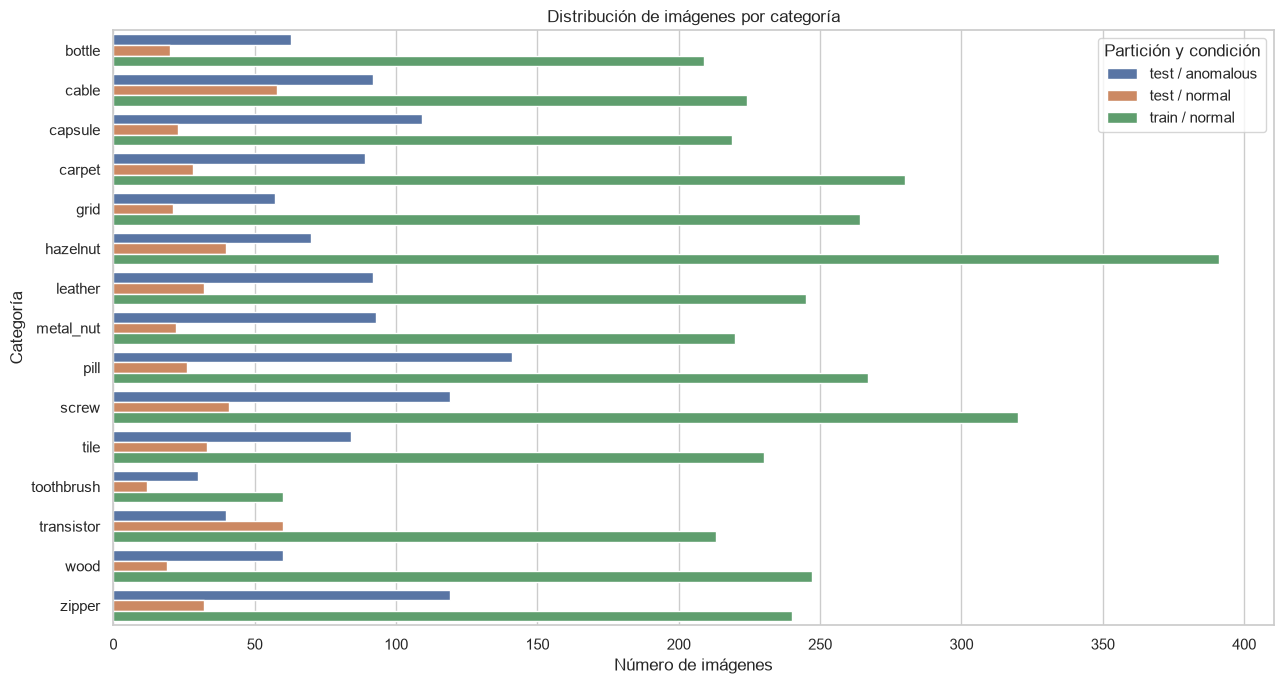

In [4]:

df_plot = (
    df_inventory
    .groupby(["category", "split", "condition"], as_index=False)
    ["n_images"].sum()
)

df_plot["group"] = (df_plot["split"] + " / " + df_plot["condition"])

plt.figure(figsize=(13, 7))

sns.barplot(
    data=df_plot,
    x="n_images",
    y="category",
    hue="group"
)

plt.title("Distribución de imágenes por categoría")
plt.xlabel("Número de imágenes")
plt.ylabel("Categoría")
plt.legend(title="Partición y condición")
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "image_distribution.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()



## Exploración visual de las categorías

Se presenta una imagen normal de entrenamiento por categoría para reconocer las diferencias visuales entre objetos y texturas

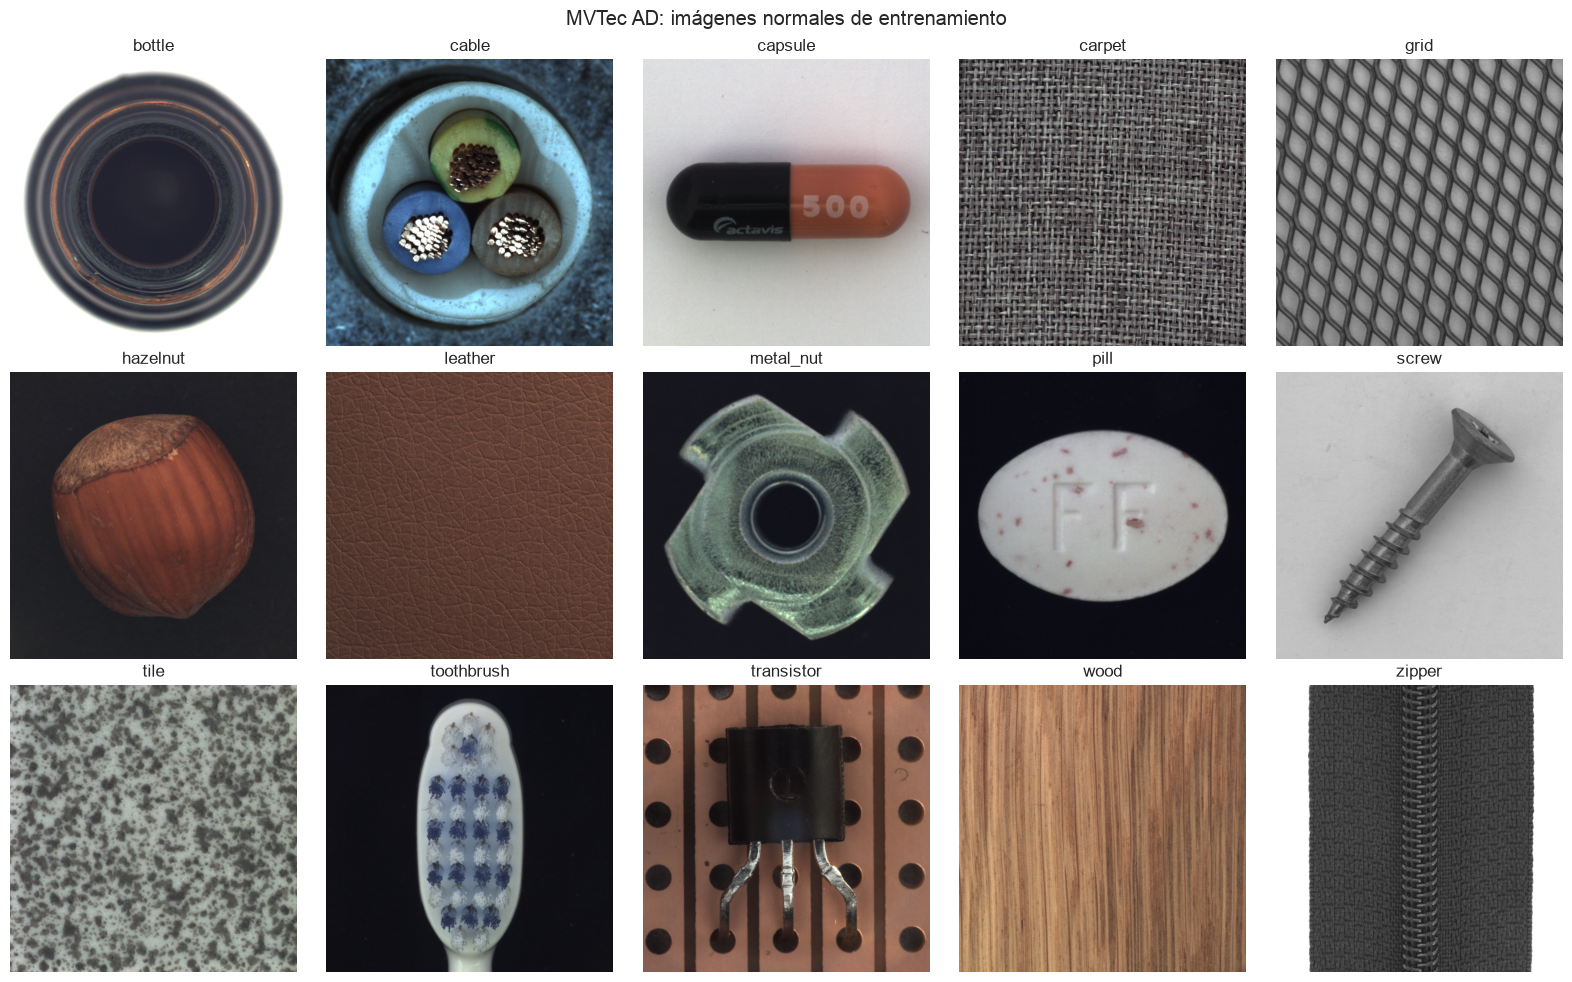

In [5]:

fig, axes = plt.subplots(3, 5, figsize=(16, 10))

for ax, category in zip(axes.flat, CATEGORIES):
    image_paths = sorted(
        (DATA_DIR / category / "train" / "good").glob("*.png")
    )

    if not image_paths:
        raise FileNotFoundError(
            f"No hay imágenes normales para {category}"
        )

    with Image.open(image_paths[0]) as img:
        image = img.convert("RGB").copy()

    ax.imshow(image)
    ax.set_title(category)
    ax.axis("off")

plt.suptitle("MVTec AD: imágenes normales de entrenamiento")
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "normal_samples.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()


## Dimensiones de las imágenes

Se inspeccionan las resoluciones originales del dataset para identificar diferencias entre categorías y determinar las necesidades de preprocesamiento

In [6]:

dimension_rows = []

for category in CATEGORIES:
    category_dir = DATA_DIR / category

    for split in ["train", "test"]:
        for image_path in sorted((category_dir / split).glob("*/*.png")):
            with Image.open(image_path) as image:
                width, height = image.size

            dimension_rows.append({
                "category": category,
                "split": split,
                "width": width,
                "height": height,
                "megapixels": width * height / 1_000_000
            })

df_dimensions = pd.DataFrame(dimension_rows)

display(
    df_dimensions.groupby("category").agg(
        n_images=("width", "size"),
        min_width=("width", "min"),
        max_width=("width", "max"),
        min_height=("height", "min"),
        max_height=("height", "max")
    )
)

print("Resoluciones distintas:")
display(
    df_dimensions[["width", "height"]]
    .value_counts()
    .reset_index(name="n_images")
)

df_dimensions.to_csv(RESULTS_DIR / "image_dimensions.csv", index=False)


,n_images,min_width,max_width,min_height,max_height
category,,,,,
bottle,292,900,900,900,900
cable,374,1024,1024,1024,1024
capsule,351,1000,1000,1000,1000
carpet,397,1024,1024,1024,1024
grid,342,1024,1024,1024,1024
hazelnut,501,1024,1024,1024,1024
leather,369,1024,1024,1024,1024
metal_nut,335,700,700,700,700
pill,434,800,800,800,800


Resoluciones distintas:


,width,height,n_images
0,1024,1024,3595
1,800,800,434
2,1000,1000,351
3,840,840,347
4,700,700,335
5,900,900,292



## Integridad de las anotaciones de anomalías

Se verifica la correspondencia entre cada imagen defectuosa de prueba y su máscara de segmentación  

La comprobación incluye existencia, dimensiones y presencia de píxeles etiquetados como anómalos

In [7]:

mask_rows = []

for category in CATEGORIES:
    root = DATA_DIR / category

    for defect_dir in sorted((root / "test").iterdir()):
        if not defect_dir.is_dir() or defect_dir.name == "good":
            continue

        for image_path in sorted(defect_dir.glob("*.png")):
            mask_path = (
                root / "ground_truth"
                / defect_dir.name
                / f"{image_path.stem}_mask.png"
            )

            exists = mask_path.is_file()
            same_size = False
            has_defect_pixels = False

            if exists:
                with Image.open(image_path) as img:
                    image_size = img.size

                with Image.open(mask_path) as mask:
                    same_size = mask.size == image_size
                    has_defect_pixels = np.any(np.asarray(mask.convert("L")) > 0)

            mask_rows.append({
                "category": category,
                "defect_type": defect_dir.name,
                "image": image_path.name,
                "mask_exists": exists,
                "same_size": same_size,
                "has_defect_pixels": bool(has_defect_pixels)
            })

df_masks = pd.DataFrame(mask_rows)

mask_summary = df_masks.groupby("category").agg(
    defective_images=("image", "size"),
    masks_found=("mask_exists", "sum"),
    matching_dimensions=("same_size", "sum"),
    nonempty_masks=("has_defect_pixels", "sum")
)

display(mask_summary)

df_masks.to_csv(
    RESULTS_DIR / "mask_integrity.csv",
    index=False
)

problems = df_masks[
    ~(
        df_masks["mask_exists"]
        & df_masks["same_size"]
        & df_masks["has_defect_pixels"]
    )
]

print("Anotaciones con problemas detectados:", len(problems))
display(problems.head(20))


,defective_images,masks_found,matching_dimensions,nonempty_masks
category,,,,
bottle,63,63,63,63
cable,92,92,92,92
capsule,109,109,109,109
carpet,89,89,89,89
grid,57,57,57,57
hazelnut,70,70,70,70
leather,92,92,92,92
metal_nut,93,93,93,93
pill,141,141,141,141


Anotaciones con problemas detectados: 0


,category,defect_type,image,mask_exists,same_size,has_defect_pixels



## Ejemplos de anotaciones de anomalías

Se visualizan ejemplos de imágenes defectuosas junto con sus máscaras oficiales para comprobar cualitativamente la naturaleza de las anotaciones

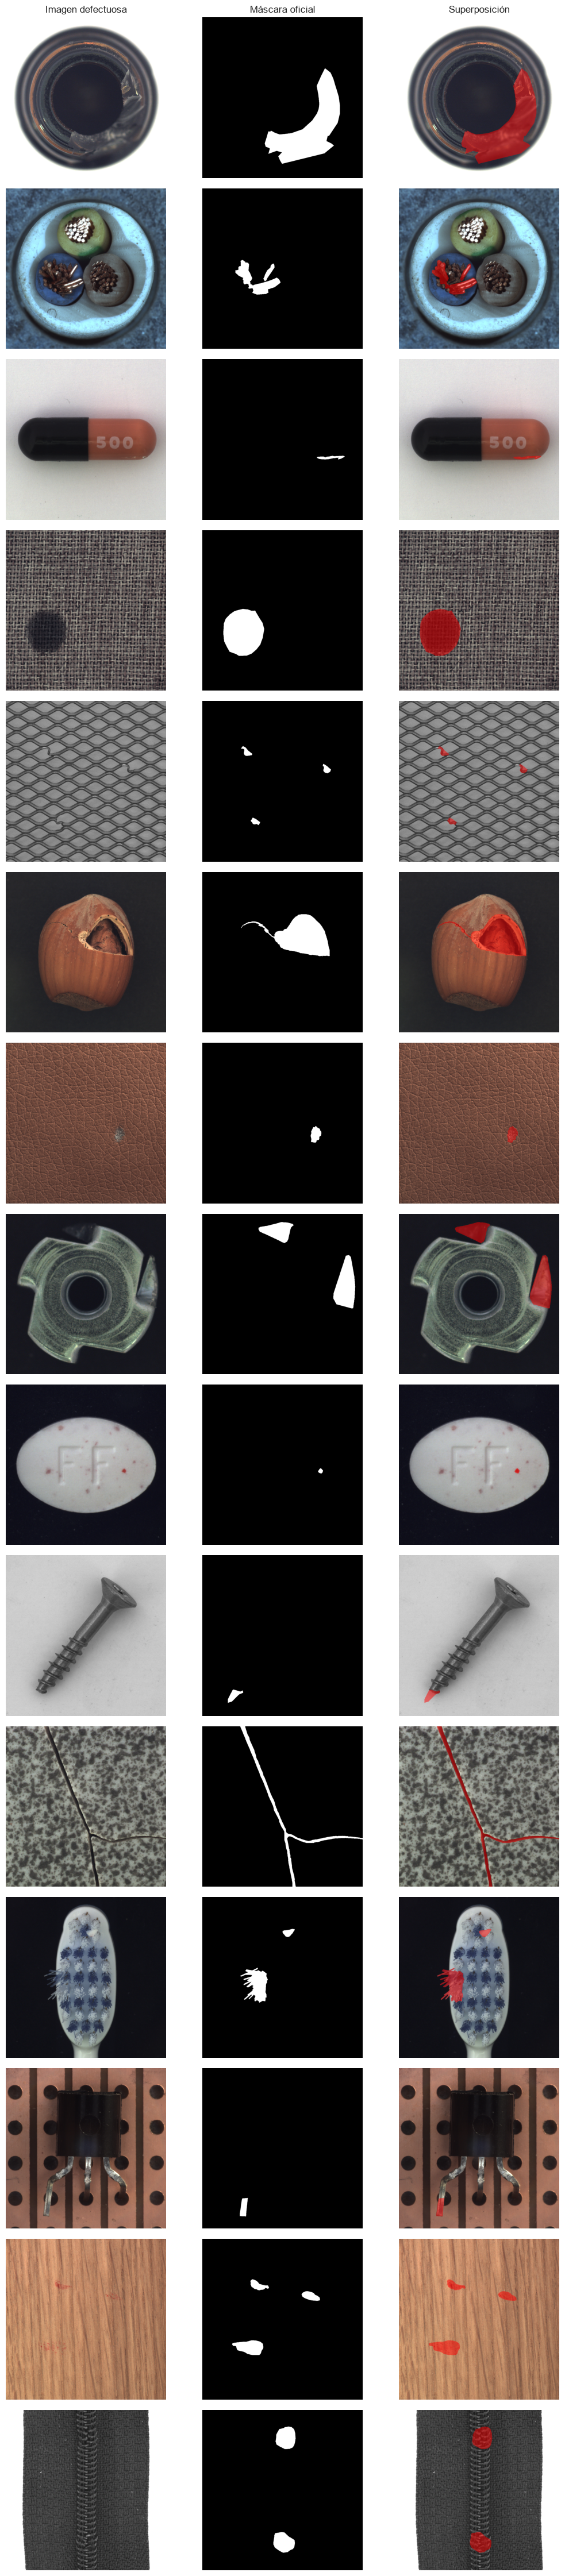

In [8]:

fig, axes = plt.subplots(len(CATEGORIES), 3, figsize=(11, 3 * len(CATEGORIES)))

for row, category in enumerate(CATEGORIES):
    root = DATA_DIR / category

    defect_images = sorted(
        path
        for path in (root / "test").glob("*/*.png")
        if path.parent.name != "good"
    )

    if not defect_images:
        raise RuntimeError(f"Sin ejemplos defectuosos: {category}")

    image_path = defect_images[0]
    mask_path = (
        root / "ground_truth"
        / image_path.parent.name
        / f"{image_path.stem}_mask.png"
    )

    with Image.open(image_path) as img:
        image = np.asarray(img.convert("RGB"))

    with Image.open(mask_path) as mask:
        mask_array = np.asarray(mask.convert("L")) > 0

    overlay = image.copy()
    overlay[mask_array] = (
        0.5 * overlay[mask_array]
        + 0.5 * np.array([255, 0, 0])
    ).astype(np.uint8)

    axes[row, 0].imshow(image)
    axes[row, 1].imshow(mask_array, cmap="gray")
    axes[row, 2].imshow(overlay)

    axes[row, 0].set_ylabel(category, rotation=0, labelpad=55)

    for ax in axes[row]:
        ax.axis("off")

axes[0, 0].set_title("Imagen defectuosa")
axes[0, 1].set_title("Máscara oficial")
axes[0, 2].set_title("Superposición")

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "anomaly_mask_examples.png",
    dpi=120,
    bbox_inches="tight"
)
plt.show()



## Síntesis del análisis exploratorio

In [9]:

summary = {
    "categories_expected": len(CATEGORIES),
    "categories_verified": int(
        status[["train_good", "test", "ground_truth"]]
        .all(axis=1).sum()
    ),
    "total_images": int(df_inventory["n_images"].sum()),
    "train_images": int(
        df_inventory.loc[
            df_inventory["split"] == "train",
            "n_images"
        ].sum()
    ),
    "test_images": int(
        df_inventory.loc[
            df_inventory["split"] == "test",
            "n_images"
        ].sum()
    ),
    "defective_test_images": len(df_masks),
    "missing_masks": int((~df_masks["mask_exists"]).sum()),
    "dimension_mismatches": int(
        (df_masks["mask_exists"] & ~df_masks["same_size"]).sum()
    ),
    "empty_masks": int(
        (df_masks["mask_exists"] & ~df_masks["has_defect_pixels"]).sum()
    ),
    "unique_resolutions": int(
        df_dimensions[["width", "height"]]
        .drop_duplicates().shape[0]
    )
}

display(pd.DataFrame([summary]).T.rename(columns={0: "value"}))

pd.Series(summary).to_json(
    RESULTS_DIR / "eda_summary.json",
    indent=2
)

assert df_inventory.loc[
    (df_inventory["split"] == "train")
    & (df_inventory["condition"] != "normal"),
    "n_images"
].sum() == 0, "Se encontraron defectos en el train oficial."

print("Resumen guardado en:", RESULTS_DIR)


,value
categories_expected,15
categories_verified,15
total_images,5354
train_images,3629
test_images,1725
defective_test_images,1258
missing_masks,0
dimension_mismatches,0
empty_masks,0
unique_resolutions,6


Resumen guardado en: /Users/diana/Study/Master/Técnicas Avanzadas de Modelado/mvtec-ad-cnn-benchmark/results/eda



## Conclusiones del análisis exploratorio

### Composición del dataset

Se verificaron las 15 categorías de MVTec AD, con 5.354 imágenes: 3.629 normales de entrenamiento y 1.725 de prueba, de las cuales 1.258 contienen anomalías  

La cantidad de imágenes no es uniforme entre categorías. Por ejemplo, `hazelnut` dispone de 391 imágenes normales de entrenamiento, mientras que `toothbrush` tiene 60. También existen diferencias en la cantidad de tipos de defectos   

### Características visuales y resolución

El dataset contiene objetos y texturas con diferentes características geométricas y superficiales. Se identificaron seis resoluciones originales, entre 700 × 700 y 1024 × 1024 píxeles   

La exploración de las máscaras muestra defectos de distintas formas y tamaños, incluidas regiones extensas, anomalías pequeñas y estructuras delgadas  
### Calidad de las anotaciones

Se verificó la existencia de las 1.258 máscaras correspondientes a imágenes defectuosas. No se detectaron máscaras faltantes, incompatibilidades de dimensiones ni máscaras vacías

### Limitaciones y riesgos metodológicos

- La cantidad de imágenes y la variedad de defectos difieren entre categorías
- El entrenamiento oficial contiene únicamente imágenes normales
- Reducir la resolución puede eliminar detalles importantes para la localización


## Auditoría de imágenes duplicadas

Se calculan huellas SHA-256 de las imágenes originales para identificar archivos exactamente duplicados dentro del dataset y comprobar si existen coincidencias entre entrenamiento y prueba  

El análisis se realiza sobre los archivos originales, sin aplicar transformaciones ni redimensionamientos  

Esta comprobación permite identificar duplicados exactos, pero no descarta imágenes casi idénticas ni posibles dependencias derivadas de una misma sesión de captura  

In [10]:
def file_sha256(path):
    digest = hashlib.sha256()

    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)

    return digest.hexdigest()


records = []

for category in CATEGORIES:
    for split in ["train", "test"]:
        for path in sorted(
            (DATA_DIR / category / split).glob("*/*.png")
        ):
            records.append({
                "category": category,
                "split": split,
                "path": str(path.relative_to(DATA_DIR)),
                "sha256": file_sha256(path)
            })

df_hashes = pd.DataFrame(records)

# Archivos con hashes repetidos
duplicates = df_hashes[df_hashes.duplicated("sha256", keep=False)].sort_values("sha256")

# Coincidencias entre train y test
hashes_train = set(df_hashes.loc[df_hashes["split"] == "train", "sha256"])
hashes_test = set(df_hashes.loc[df_hashes["split"] == "test", "sha256"])
shared_hashes = hashes_train & hashes_test

print("Archivos analizados:", len(df_hashes))
print("Archivos involucrados en duplicados:", len(duplicates))
print("Hashes compartidos train/test:", len(shared_hashes))

display(duplicates.head(30))
duplicates.to_csv(RESULTS_DIR / "duplicate_images.csv", index=False)

assert len(df_hashes) == summary["total_images"]

Archivos analizados: 5354
Archivos involucrados en duplicados: 0
Hashes compartidos train/test: 0


,category,split,path,sha256
